# Degeneracy and empirical solution distributions

Examine distributional features without treating optimizer restarts as independent experimental data.

**Data:** the frozen 3000-run production set (`data/raw`). **Acceptance:** all five normalized residual magnitudes strictly below one. These are *numerical widths*, not independently measured Gaussian standard deviations.

> Start from the repository root or its `notebooks/` folder. No recomputation of the 3000 DE optimizations is required.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Works in Jupyter, VS Code, and Colab if the repository is cloned locally.
workdir = Path.cwd().resolve()
candidates = [workdir, workdir.parent]
ROOT = next((p for p in candidates if (p / "data/raw/runs.csv").is_file()
             and (p / "src/model.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError(
        "Cannot find the repository root. Open the project folder (with data/ and src/) "
        "or clone the repository in the Colab session before running the notebook."
    )
sys.path.insert(0, str(ROOT / "src"))
from model import PARAMETERS, V_EW, MASS_WIDTHS, mass_matrix, spectrum
raw = pd.read_csv(ROOT / "data/raw/runs.csv")
print(f"Repository: {ROOT.name}; records: {len(raw):,}; v = {V_EW} GeV")

Repository: DE_Particle_paper_public; records: 3,000; v = 246.22 GeV


In [2]:
residual_cols = ["z_H1", "z_H2", "z_H3", "z_charged", "z_kappa"]
z_abs = np.abs(raw[residual_cols].to_numpy(float))
mask_mass = (z_abs[:, :3] < 1).all(axis=1)
mask_charged = z_abs[:, 3] < 1
mask_kappa = z_abs[:, 4] < 1
mask_all = (z_abs < 1).all(axis=1)
accepted = raw.loc[mask_all].copy()
representative = (accepted.sort_values(["target_index", "loss", "restart"])
                  .drop_duplicates("target_index").sort_values("target_index"))
assert len(raw) == 3000 and len(accepted) == 2971 and len(representative) == 1000

## Strong but selection-dependent correlations\n`representative` takes the lowest-loss **accepted** candidate per target. `accepted` retains every reconstruction satisfying the five strict final criteria. A loss-minimizing representative can conceal less frequently reached solution branches.

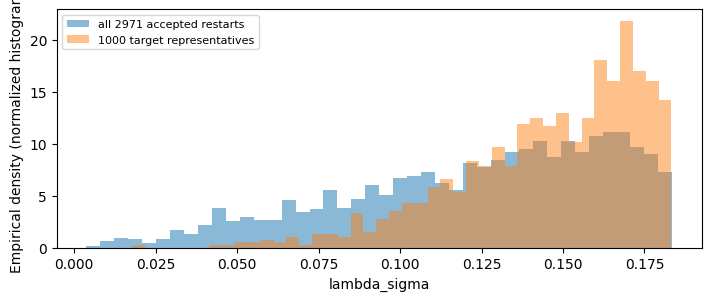

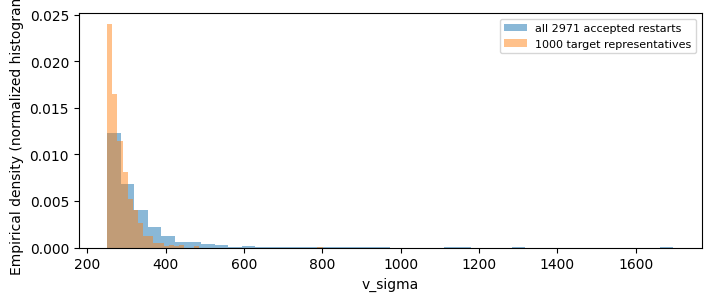

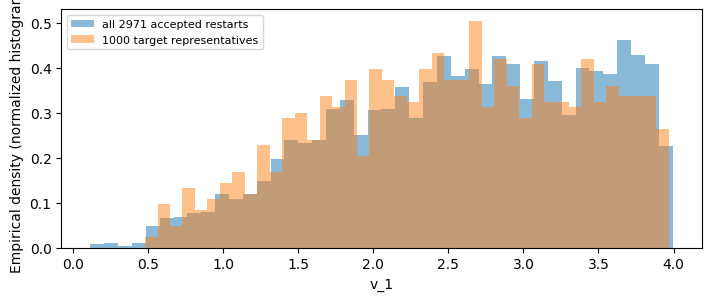

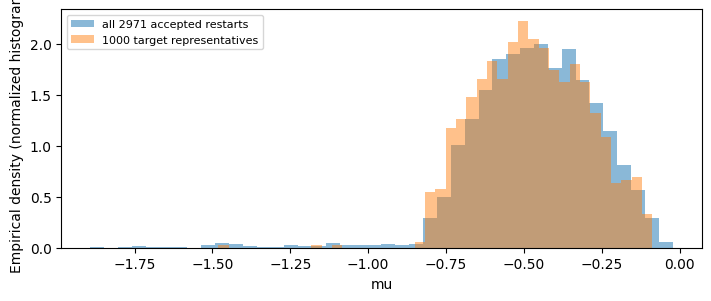

In [3]:
for key in ["lambda_sigma","v_sigma","v_1","mu"]:
    fig,ax=plt.subplots(figsize=(7,2.9),layout="constrained")
    ax.hist(accepted[key],bins=42,density=True,alpha=.52,label="all 2971 accepted restarts")
    ax.hist(representative[key],bins=42,density=True,alpha=.48,label="1000 target representatives")
    ax.set_xlabel(key);ax.set_ylabel("Empirical density (normalized histogram)");ax.legend(fontsize=8)
    plt.show()

## Same-target spread\nA target may have markedly different preimages. The quantity below is the range of `v_sigma` over restarts for each target, computed only when multiple accepted runs exist.

count    1000.000000
mean      111.911645
std       116.024673
min         0.694799
25%        42.109100
50%        79.521177
75%       138.794207
95%       309.089998
max       966.579124
Median accepted same-target v_sigma range (GeV): 79.52117686047062


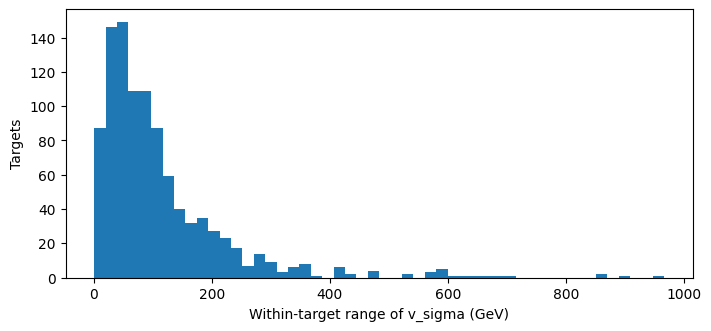

In [4]:
span=accepted.groupby("target_index")["v_sigma"].agg(lambda x:x.max()-x.min())
print(span.describe(percentiles=[.25,.50,.75,.95]).to_string())
print("Median accepted same-target v_sigma range (GeV):",span.median())
fig,ax=plt.subplots(figsize=(7,3.2),layout="constrained")
ax.hist(span,bins=50);ax.set_xlabel("Within-target range of v_sigma (GeV)");ax.set_ylabel("Targets")
plt.show()

## Two-parameter structure\nCorrelations here describe the empirical reconstruction ensemble. They are not, by themselves, posterior constraints or evidence of a unique physical mechanism.

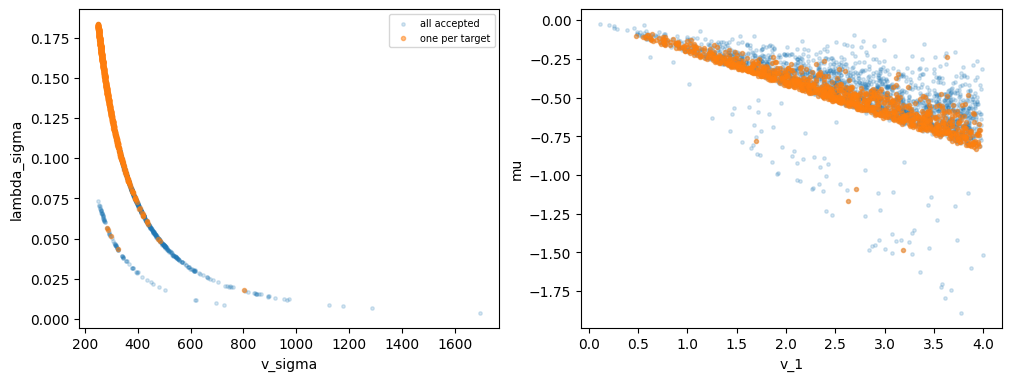

In [5]:
fig,axes=plt.subplots(1,2,figsize=(10,3.7),layout="constrained")
for ax,key1,key2 in zip(axes,["v_sigma","v_1"],["lambda_sigma","mu"]):
    ax.scatter(accepted[key1],accepted[key2],s=6,alpha=.18,label="all accepted")
    ax.scatter(representative[key1],representative[key2],s=9,alpha=.5,label="one per target")
    ax.set_xlabel(key1);ax.set_ylabel(key2)
axes[0].legend(fontsize=7)
plt.show()